<a href="https://colab.research.google.com/github/lizza-mar/Bonus-2/blob/main/Bonus_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Parte 1 del Bonus

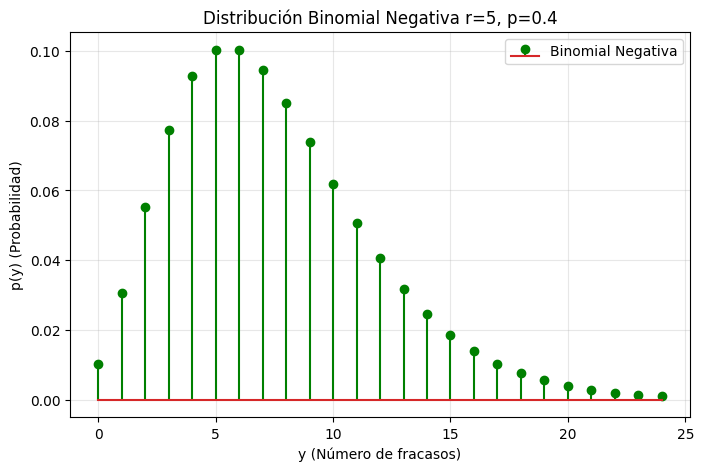

In [3]:
import numpy as np  # Importa la librería numpy para manejar arreglos numéricos
import matplotlib.pyplot as plt  # Importa matplotlib para crear las gráficas
from scipy.stats import nbinom  # Importa la función de la Distribución Binomial Negativa

# Parámetros de la distribución
r = 5  # Número de éxitos requeridos (equivalente a 'n' en scipy)
p = 0.4  # Probabilidad de éxito en cada ensayo

# Definimos el rango de valores posibles para 'y' (número de fracasos antes de r éxitos)
y = np.arange(0, 25)  # Crea un arreglo de enteros desde 0 hasta 24

# Calculamos las probabilidades teóricas p(y)
py = nbinom.pmf(y, r, p)  # Calcula la Función de Masa de Probabilidad (PMF) para cada valor de y

# Graficando la distribución de probabilidad
plt.figure(figsize=(8, 5))  # Crea una figura o lienzo de 8x5 pulgadas

plt.title(f"Distribución Binomial Negativa r={r}, p={p}")  # Agrega el título dinámico con los parámetros

# Grafica los puntos y líneas verticales (gráfico de tallo)
plt.stem(y, py, markerfmt='o', linefmt='green', label='Binomial Negativa')  # Dibuja los tallos en verde con círculos

plt.xlabel("y (Número de fracasos)")  # Etiqueta el eje horizontal (X)
plt.ylabel("p(y) (Probabilidad)")  # Etiqueta el eje vertical (Y)

# Estilo adicional para completar el gráfico
plt.legend()  # Muestra el recuadro con la etiqueta 'Binomial Negativa'
plt.grid(True, alpha=0.3)  # Agrega una cuadrícula de fondo con transparencia del 30%
plt.show()  # Despliega el gráfico final en pantalla

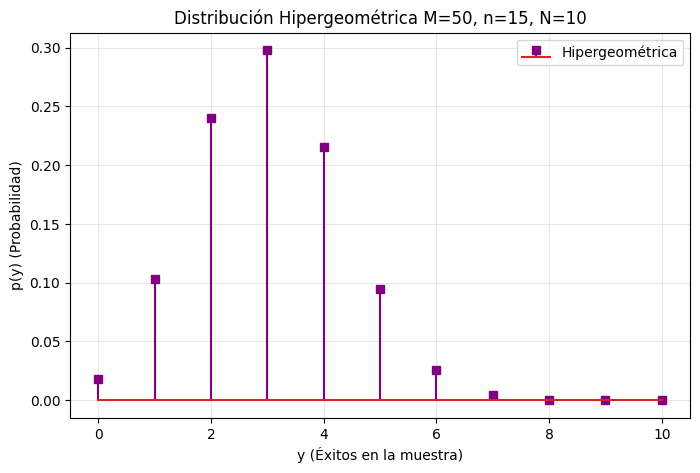

In [4]:
import numpy as np  # Importa la librería numpy para manejar arreglos numéricos
import matplotlib.pyplot as plt  # Importa matplotlib para crear las gráficas
from scipy.stats import hypergeom  # Importa la función de la Distribución Hipergeométrica

# Parámetros de la distribución
M = 50  # Tamaño total de la población (ej. total de cartas o piezas)
n = 15  # Número total de elementos de éxito en la población
N = 10  # Tamaño de la muestra extraída (sin reemplazo)

# Definimos el rango de valores posibles para 'y' (éxitos en la muestra)
# El mínimo posible es max(0, N - (M - n)) y el máximo es min(n, N)
y = np.arange(max(0, N - (M - n)), min(n, N) + 1)  # Genera los valores válidos que puede tomar y

# Calculamos las probabilidades teóricas p(y)
py = hypergeom.pmf(y, M, n, N)  # Calcula la Función de Masa de Probabilidad (PMF) hipergeométrica

# Graficando la distribución de probabilidad
plt.figure(figsize=(8, 5))  # Crea una figura o lienzo de 8x5 pulgadas

plt.title(f"Distribución Hipergeométrica M={M}, n={n}, N={N}")  # Agrega el título con los parámetros actuales

# Grafica los puntos y líneas verticales (gráfico de tallo)
plt.stem(y, py, markerfmt='s', linefmt='purple', label='Hipergeométrica')  # Dibuja los tallos en morado con cuadrados ('s')

plt.xlabel("y (Éxitos en la muestra)")  # Etiqueta el eje horizontal (X)
plt.ylabel("p(y) (Probabilidad)")  # Etiqueta el eje vertical (Y)

# Estilo adicional para completar el gráfico
plt.legend()  # Muestra el recuadro con la etiqueta 'Hipergeométrica'
plt.grid(True, alpha=0.3)  # Agrega una cuadrícula de fondo con transparencia del 30%
plt.show()  # Despliega el gráfico final en pantalla

###Parte 2 del BONUS

In [5]:
import pandas as pd
import numpy as np
from scipy.stats import poisson
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
#Importar el archivo que vamos a analizar
df = pd.read_csv ("up08JUN.csv")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 484 entries, 0 to 483
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   ev_id         484 non-null    object 
 1   Aircraft_Key  484 non-null    int64  
 2   crew_no       484 non-null    int64  
 3   flight_type   484 non-null    object 
 4   flight_craft  484 non-null    object 
 5   flight_hours  484 non-null    float64
 6   lchg_date     484 non-null    object 
 7   Unnamed: 7    0 non-null      float64
 8   lchg_userid   484 non-null    object 
dtypes: float64(2), int64(2), object(5)
memory usage: 34.2+ KB


In [7]:
df.describe()

,Aircraft_Key,crew_no,flight_hours,Unnamed: 7
count,484.0,484.000000,484.000000,0.0
mean,1.0,1.150826,776.800413,NaN
std,0.0,0.358250,3505.830933,NaN
min,1.0,1.000000,0.000000,NaN
25%,1.0,1.000000,3.000000,NaN
50%,1.0,1.000000,30.000000,NaN
75%,1.0,1.000000,295.250000,NaN
max,1.0,2.000000,55000.000000,NaN


Limpiamos la base de datos, para esto se deben eliminar los datos duplicados y contar los accidentes por mes, incluyendo los meses que no hubo accidentes

In [8]:
# Queremos solo los accidentes únicos (ev_id sin repetir)
df_unicos = df[['ev_id']].drop_duplicates().copy()

# Extraer Año, Mes y Día de los primeros 8 dígitos del ev_id
df_unicos['fecha_exacta'] = pd.to_datetime(df_unicos['ev_id'].astype(str).str[:8], format='%Y%m%d')

# Agrupar por Año-Mes
df_unicos['anio_mes'] = df_unicos['fecha_exacta'].dt.to_period('M').dt.to_timestamp()
conteo_mensual = df_unicos.groupby('anio_mes').size()

# Crear el calendario completo desde el primer mes hasta el último y rellenar los faltantes con 0
rango_completo = pd.date_range(start=conteo_mensual.index.min(), end=conteo_mensual.index.max(), freq='MS')
conteo_mensual = conteo_mensual.reindex(rango_completo, fill_value=0)

print(f"Total de accidentes únicos: {len(df_unicos)}")
print(f"Total de meses analizados: {len(conteo_mensual)}")
print(f"Meses con 0 accidentes: {(conteo_mensual == 0).sum()}")
print("\nConteo por mes:")
print(conteo_mensual)

Total de accidentes únicos: 30
Total de meses analizados: 186
Meses con 0 accidentes: 174

Conteo por mes:
2008-06-01    1
2008-07-01    0
2008-08-01    0
2008-09-01    0
2008-10-01    0
             ..
2023-07-01    0
2023-08-01    1
2023-09-01    0
2023-10-01    3
2023-11-01    4
Freq: MS, Length: 186, dtype: int64


Calculamos la Media (Lambda), Varianza y la Probabilidad de Poisson

### Modelo Teórico: Distribución de Poisson
Sea $Y$ el número de accidentes de avión ocurridos en un intervalo de un mes. Si $Y$ sigue una distribución de Poisson, su función de probabilidad es:

$$p(y) = \frac{\lambda^y}{y!} e^{-\lambda}, \quad y = 0, 1, 2, \dots, \quad \lambda > 0$$

Donde los parámetros teóricos son:
* **Valor esperado (Media):** $\mu = E(Y) = \lambda$
* **Varianza:** $\sigma^2 = V(Y) = \lambda$


In [9]:
#CÁLCULO DE PARÁMETROS Y POISSON


# 1. Estimación de la lambda usando el promedio muestral (mu = E(Y) = lambda)
lam = conteo_mensual.mean()

# 2. Varianza muestral para compararla con la varianza teórica (V(Y) = lambda)
varianza_muestral = conteo_mensual.var()
desv_estandar = np.sqrt(lam) # sigma = sqrt(lambda)

print(f"Media estimada / Lambda (μ = λ): {lam:.4f} accidentes/mes")
print(f"Varianza teórica de Poisson (σ² = λ): {lam:.4f}")
print(f"Varianza real de los datos (s²): {varianza_muestral:.4f}")
print(f"Desviación estándar teórica (σ = √λ): {desv_estandar:.4f}\n")

# 3. Valores posibles de la variable aleatoria Y (y = 0, 1, 2, ...)
valores_y = np.arange(0, conteo_mensual.max() + 1)

# 4. Probabilidad observada (frecuencia relativa real en la base de datos)
prob_observada = conteo_mensual.value_counts(normalize=True).reindex(valores_y, fill_value=0)

# 5. Probabilidad teórica p(y) = (lambda^y * e^-lambda) / y! calculada con poisson.pmf
prob_teorica = poisson.pmf(valores_y, mu=lam)

# 6. Tabla comparativa
tabla_resultados = pd.DataFrame({
    'Accidentes_mes (y)': valores_y,
    'Meses_observados': conteo_mensual.value_counts().reindex(valores_y, fill_value=0).values,
    'Prob_Observada': prob_observada.values,
    'Prob_Poisson p(y)': prob_teorica
})

print("Tabla de Distribución de Probabilidad:")
print(tabla_resultados.to_string(index=False))

Media estimada / Lambda (μ = λ): 0.1613 accidentes/mes
Varianza teórica de Poisson (σ² = λ): 0.1613
Varianza real de los datos (s²): 0.6657
Desviación estándar teórica (σ = √λ): 0.4016

Tabla de Distribución de Probabilidad:
 Accidentes_mes (y)  Meses_observados  Prob_Observada  Prob_Poisson p(y)
                  0               174        0.935484       8.510450e-01
                  1                 7        0.037634       1.372653e-01
                  2                 0        0.000000       1.106978e-02
                  3                 1        0.005376       5.951497e-04
                  4                 3        0.016129       2.399797e-05
                  5                 0        0.000000       7.741281e-07
                  6                 0        0.000000       2.080989e-08
                  7                 0        0.000000       4.794906e-10
                  8                 1        0.005376       9.667150e-12


In [10]:
# Diccionario con los nombres de los meses en español
meses_es = {
    1: 'Enero', 2: 'Febrero', 3: 'Marzo', 4: 'Abril',
    5: 'Mayo', 6: 'Junio', 7: 'Julio', 8: 'Agosto',
    9: 'Septiembre', 10: 'Octubre', 11: 'Noviembre', 12: 'Diciembre'
}

# Crear una tabla cronológica con el nombre del mes, año y cantidad de accidentes
tabla_cronologica = pd.DataFrame({
    'Mes_y_Anio': [f"{meses_es[fecha.month]} {fecha.year}" for fecha in conteo_mensual.index],
    'Accidentes': conteo_mensual.values
})

# Únicamente los 12 meses donde SÍ ocurrieron accidentes
print("MESES DONDE OCURRIERON ACCIDENTES")
print(tabla_cronologica[tabla_cronologica['Accidentes'] > 0].to_string(index=False))


MESES DONDE OCURRIERON ACCIDENTES
     Mes_y_Anio  Accidentes
     Junio 2008           1
     Abril 2022           1
     Junio 2022           1
     Julio 2022           1
Septiembre 2022           1
   Febrero 2023           1
     Marzo 2023           4
     Abril 2023           8
      Mayo 2023           4
    Agosto 2023           1
   Octubre 2023           3
 Noviembre 2023           4


In [11]:
#TODOS los 186 meses (incluyendo los 174 meses con 0 accidentes)
print("\n TODOS LOS MESES DEL PERIODO")
print(tabla_cronologica.to_string(index=False))


 TODOS LOS MESES DEL PERIODO
     Mes_y_Anio  Accidentes
     Junio 2008           1
     Julio 2008           0
    Agosto 2008           0
Septiembre 2008           0
   Octubre 2008           0
 Noviembre 2008           0
 Diciembre 2008           0
     Enero 2009           0
   Febrero 2009           0
     Marzo 2009           0
     Abril 2009           0
      Mayo 2009           0
     Junio 2009           0
     Julio 2009           0
    Agosto 2009           0
Septiembre 2009           0
   Octubre 2009           0
 Noviembre 2009           0
 Diciembre 2009           0
     Enero 2010           0
   Febrero 2010           0
     Marzo 2010           0
     Abril 2010           0
      Mayo 2010           0
     Junio 2010           0
     Julio 2010           0
    Agosto 2010           0
Septiembre 2010           0
   Octubre 2010           0
 Noviembre 2010           0
 Diciembre 2010           0
     Enero 2011           0
   Febrero 2011           0
     Marzo 2011   

Grafica de la comparción de los datos reales con los datos obtenidos por Poisson

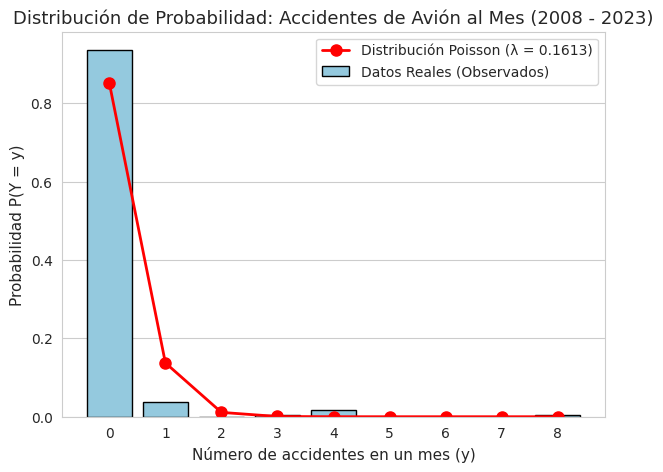

In [12]:
# GRÁFICA COMPARATIVA

sns.set_style("whitegrid")
plt.figure(figsize=(7, 5))

# 1. Barras con la probabilidad real (datos observados)
sns.barplot(x=valores_y, y=prob_observada.values, color='skyblue', edgecolor='black', label='Datos Reales (Observados)')

# 2. Línea y puntos con la distribución teórica de Poisson
plt.plot(valores_y, prob_teorica, color='red', marker='o', linewidth=2, markersize=8, label=f'Distribución Poisson (λ = {lam:.4f})')

# 3. Etiquetas y título
plt.title('Distribución de Probabilidad: Accidentes de Avión al Mes (2008 - 2023)', fontsize=13)
plt.xlabel('Número de accidentes en un mes (y)', fontsize=11)
plt.ylabel('Probabilidad P(Y = y)', fontsize=11)
plt.legend()
plt.show()

Comparación de una Gráfica de Barras con un Gráfico de Caja

###Distribución de Poisson vs Diagrama de Caja (Boxplot)

Comparación el modelo de probabilidad contra la dispersión real de los datos:

* **Distribución de Probabilidad vs Poisson):** Muestra en el eje X los posibles escenarios de accidentes al mes ($y = 0, 1, \dots, 8$) y en el eje Y su probabilidad. Confirma que los datos siguen una tendencia de Poisson fuertemente sesgada a la derecha.
* **Diagrama de Caja / Boxplot:** Nos ayuda a visualizar la dispersión y los valores atípicos de la muestra completa (**186 meses analizados**, representados como un único grupo en el eje X, mientras que el eje Y mide la cantidad de accidentes del 0 al 8).


  * **¿Por qué la caja se ve aplastada en el `0`?** El **93.5%** de los meses (174 de 186) tuvieron cero accidentes, el primer cuartil ($Q_1$), la mediana y el tercer cuartil ($Q_3$) colapsan sobre el **0**, generando un rango intercuartílico nulo ($IQR = 0$).
  * **Valores atípicos (*outliers*) y media:** El triángulo rojo señala dónde cae el promedio ($\mu = 0.1613$), mientras que los círculos flotando en **1, 3, 4 y 8** representan los meses extraordinarios donde sí ocurrieron accidentes, explicando por qué la varianza real supera a la media.


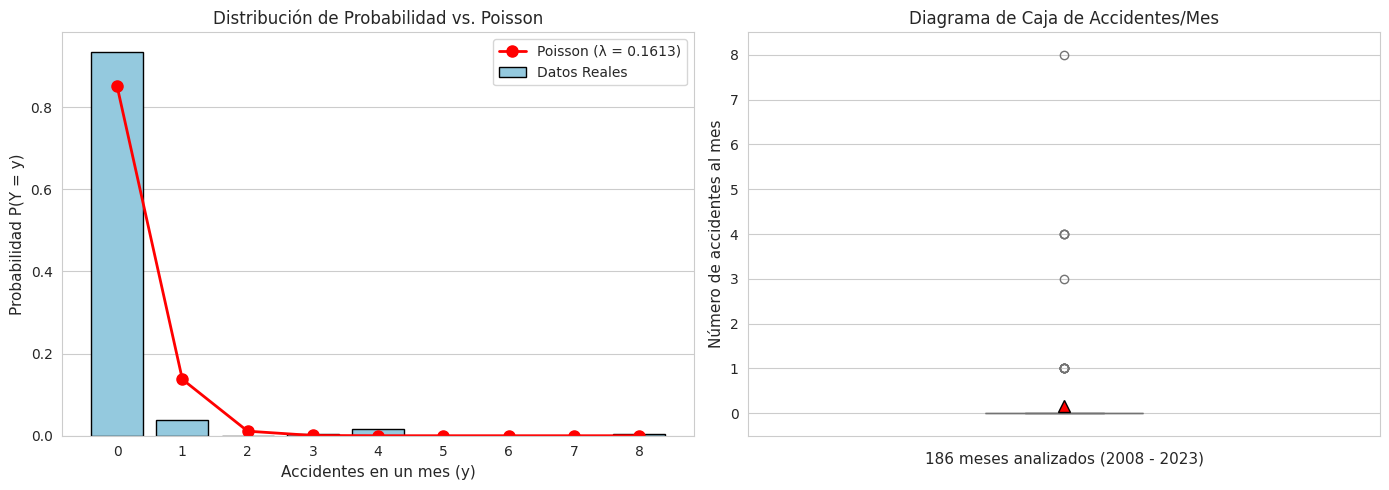

In [18]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# GRÁFICA 1: Distribución de Probabilidad
sns.barplot(x=valores_y, y=prob_observada.values, color='skyblue', edgecolor='black', label='Datos Reales', ax=axes[0])
axes[0].plot(valores_y, prob_teorica, color='red', marker='o', linewidth=2, markersize=8, label=f'Poisson (λ = {lam:.4f})')
axes[0].set_title('Distribución de Probabilidad vs. Poisson', fontsize=12)
axes[0].set_xlabel('Accidentes en un mes (y)', fontsize=11)
axes[0].set_ylabel('Probabilidad P(Y = y)', fontsize=11)
axes[0].legend()

# GRÁFICA 2: Boxplot
sns.boxplot(
    y=conteo_mensual.values,
    color='lightgreen',
    width=0.25,
    showmeans=True, # Muestra la media además de la mediana
    meanprops={"marker":"^", "markerfacecolor":"red", "markeredgecolor":"black", "markersize":"8"},
    ax=axes[1]
)

# Ajustes del Eje Y:
axes[1].set_ylim(-0.5, 8.5)                  # Margen abajo y arriba para que no se corte el 0 ni el 8
axes[1].set_yticks(np.arange(0, 9, 1))       # Muestra todos los números enteros: 0, 1, 2, 3, 4, 5, 6, 7, 8

axes[1].set_title('Diagrama de Caja de Accidentes/Mes', fontsize=12)
axes[1].set_ylabel('Número de accidentes al mes', fontsize=11)
axes[1].set_xlabel('186 meses analizados (2008 - 2023)', fontsize=11)

plt.tight_layout()
plt.show()


Medidas de Tendencia Central y Dispersión

In [14]:
# MEDIDAS DE TENDENCIA CENTRAL Y DISPERSIÓN

# Medidas de Tendencia Central
media = conteo_mensual.mean()
mediana = conteo_mensual.median()
moda = conteo_mensual.mode()

# Medidas de Dispersión
varianza_muestral = conteo_mensual.var()          # s^2
desv_estandar = conteo_mensual.std()              # s
rango = conteo_mensual.max() - conteo_mensual.min() # Máximo - Mínimo
q1 = conteo_mensual.quantile(0.25)                # Primer cuartil (25%)
q3 = conteo_mensual.quantile(0.75)                # Tercer cuartil (75%)
iqr = q3 - q1                                     # Rango Intercuartílico (Q3 - Q1)

print("MEDIDAS DE TENDENCIA CENTRAL")
print(f"Media (Promedio):        {media:.4f} accidentes/mes")
print(f"Mediana:                 {mediana:.4f} accidentes/mes")
print(f"Moda:                    {moda} accidentes/mes\n")

print("MEDIDAS DE DISPERSIÓN")
print(f"Varianza muestral (s²):  {varianza_muestral:.4f}")
print(f"Desviación estándar (s): {desv_estandar:.4f} accidentes/mes")
print(f"Rango (Máx - Mín):       {rango} accidentes (de {conteo_mensual.min()} a {conteo_mensual.max()})")
print(f"Rango Intercuartílico:   {iqr:.4f} (Q1 = {q1}, Q3 = {q3})")

MEDIDAS DE TENDENCIA CENTRAL
Media (Promedio):        0.1613 accidentes/mes
Mediana:                 0.0000 accidentes/mes
Moda:                    0    0
dtype: int64 accidentes/mes

MEDIDAS DE DISPERSIÓN
Varianza muestral (s²):  0.6657
Desviación estándar (s): 0.8159 accidentes/mes
Rango (Máx - Mín):       8 accidentes (de 0 a 8)
Rango Intercuartílico:   0.0000 (Q1 = 0.0, Q3 = 0.0)


###Distribución de Probabilidad, Tendencia Central y Dispersión

**Gráfico de barras** (accidentes enteros)

* **Interpretación de las barras azules (Datos Reales)**
  * En el **eje horizontal (X)** tenemos cuántos accidentes ocurrieron en un mismo mes (`0, 1, 2... hasta 8`), y en el **eje vertical (Y)** su probabilidad.
  * Casi toda la información se concentra del lado izquierdo: el **93.5%** de los meses tuvieron **0 accidentes** y el **3.8%** tuvieron **1 accidente**. Los porcentajes pequeños hacia la derecha (**0.5%** en 3, **1.6%** en 4 y **0.5%** en 8) son meses atípicos que estiran la "cola" o "punta" de la gráfica hacia la derecha.

* **Comparación con la Distribución de Poisson (línea roja)**
  * La línea roja muestra lo que predice la fórmula matemática de Poisson usando nuestro promedio ($\lambda = 0.1613$).
  * Ambas siguen exactamente la misma forma descendente pegada al cero (Poisson predice un **85.1%** para `0` accidentes y **13.7%** para `1` accidente). La diferencia es que se obtuvo más meses en cero de lo esperado y unos pocos meses extremos (4 y 8 accidentes) donde la línea roja ya casi toca el suelo.

* **Glosario**
  * **Línea punteada verde (`Mediana y Moda = 0`):** Cae justo en el centro de la barra del `0`, confirmando que lo más común y el punto medio de los datos es que no haya accidentes.
  * **Línea discontinua café/roja (`Media μ = 0.1613`):** Está ligeramente recorrida a la derecha del `0`. Esto demuestra visualmente el **sesgo a la derecha**: los pocos meses con 3, 4 y 8 accidentes jalan el promedio por encima de la mediana.
  * **Línea naranja (`+1 Desv. Estándar = 0.9772`):** Marca hasta dónde llega la dispersión normal respecto a la media ($\mu + s$). Todo lo que queda a la derecha de esta línea naranja (los meses con 1, 3, 4 y 8 accidentes) confirma por qué la varianza real fue mayor que la media.


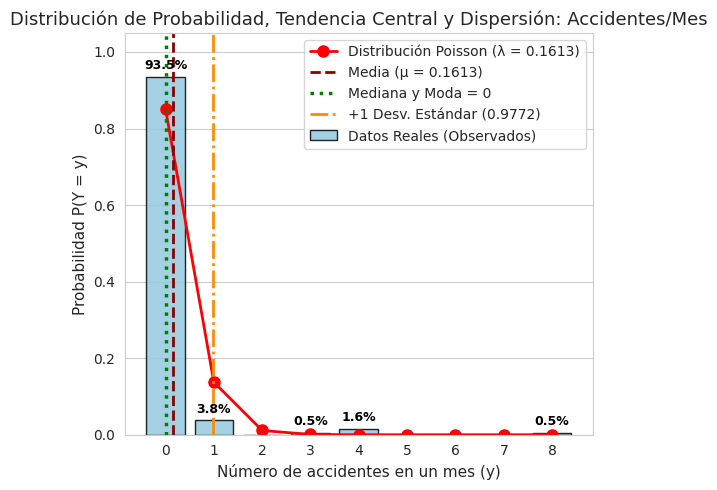

In [17]:
# GRÁFICA DE BARRAS: DISTRIBUCIÓN Y MEDIDAS

sns.set_style("whitegrid")
plt.figure(figsize=(5.5, 5))

# 1. Barras con la probabilidad real (datos observados)
ax = sns.barplot(x=valores_y, y=prob_observada.values, color='skyblue', edgecolor='black', alpha=0.85, label='Datos Reales (Observados)')

# 2. Curva teórica de Poisson
plt.plot(valores_y, prob_teorica, color='red', marker='o', linewidth=2, markersize=8, label=f'Distribución Poisson (λ = {media:.4f})')

# 3. Líneas verticales de Tendencia Central y Dispersión
plt.axvline(media, color='darkred', linestyle='--', linewidth=2, label=f'Media (μ = {media:.4f})')
plt.axvline(mediana, color='green', linestyle=':', linewidth=2.5, label=f'Mediana y Moda = {mediana:.0f}')
plt.axvline(media + desv_estandar, color='darkorange', linestyle='-.', linewidth=2, label=f'+1 Desv. Estándar ({media + desv_estandar:.4f})')

# 4. Agregar el porcentaje exacto encima de cada barra para facilitar la lectura
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        ax.annotate(f'{altura*100:.1f}%',
                    (p.get_x() + p.get_width() / 2., altura),
                    ha='center', va='bottom', fontsize=9, fontweight='bold', color='black', xytext=(0, 3), textcoords='offset points')

# 5. Títulos y etiquetas
plt.title('Distribución de Probabilidad, Tendencia Central y Dispersión: Accidentes/Mes', fontsize=13)
plt.xlabel('Número de accidentes en un mes (y)', fontsize=11)
plt.ylabel('Probabilidad P(Y = y)', fontsize=11)
plt.ylim(0, 1.05) # Da margen arriba para que se vea bien el texto de 93.5%
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

**NOTA:** Si cambiamos el intervalo por **AÑOS**, se debe ajustar el parámetro a $\lambda^* = m \cdot \lambda$ ( $\lambda^* = \mu \cdot \lambda$).




### Interpretación: Gráfica Descriptiva de los 12 Meses Activos

Ahora veremos la gráfica de barras descriptiva enfocada exclusivamente en los **12 meses en los que sí ocurrieron accidentes** (dejando fuera los 174 meses donde el conteo fue cero).

* **EJES:**

 En el **eje horizontal (X)** se ordenan cronológicamente los 12 meses activos con su año correspondiente.

 En el **eje vertical (Y)** se muestra la cantidad exacta de accidentes ocurridos en cada uno, sumando en total los **30 accidentes únicos** de la base de datos.


* **Comportamiento cronológico y picos:**
  * Durante los primeros 6 meses activos registrados (**Junio 2008, Abril, Junio, Julio, Septiembre de 2022 y Febrero de 2023**), además de **Agosto de 2023**, la incidencia se mantuvo baja y constante en **1 solo accidente por mes** (7 meses en total).


  * A partir de **marzo de 2023** se observa un repunte concentrado: se registraron **4 accidentes** en **Marzo, Mayo y Noviembre de 2023**, **3 accidentes** en **Octubre de 2023**, y un pico atípico máximo de **8 accidentes en Abril de 2023** (que representa por sí solo más de una cuarta parte de todos los accidentes de la muestra).


* **Nota:** Esta gráfica es solo descriptiva, solo nos ayuda a ubicar fechas clave. No se utiliza para calcular la distribución de Poisson porque, al omitir los meses con `0` accidentes, se elimina una parte fundamental del espacio muestral ($y = 0, 1, 2, \dots$) y se altera el promedio real ($\lambda = 0.1613$).


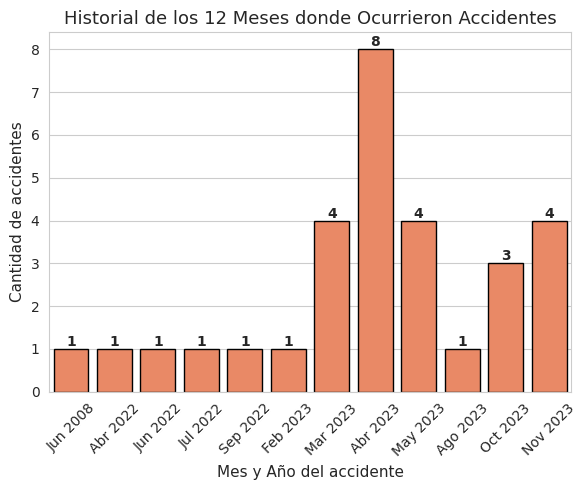

In [20]:
#GRÁFICA DESCRIPTIVA DE LOS 12 MESES ACTIVOS


meses_es = {1:'Ene', 2:'Feb', 3:'Mar', 4:'Abr', 5:'May', 6:'Jun',
            7:'Jul', 8:'Ago', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dic'}

# Filtrar solo los meses donde hubo al menos 1 accidente
meses_activos = conteo_mensual[conteo_mensual > 0]
nombres_meses = [f"{meses_es[f.month]} {f.year}" for f in meses_activos.index]

sns.set_style("whitegrid")
plt.figure(figsize=(6, 5))
ax = sns.barplot(x=nombres_meses, y=meses_activos.values, color='coral', edgecolor='black')

# Poner el número exacto de accidentes encima de cada barra
# Los métodos .get_height(), .get_x() y .get_width() leen su altura, borde izquierdo y ancho
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), # Extrae la altura como texto y ubica el centro superior (X, Y)
                ha='center', va='bottom', fontsize=10, fontweight='bold') # Centra el texto horizontalmente, lo apoya sobre el borde y lo pone en negritas


plt.title('Historial de los 12 Meses donde Ocurrieron Accidentes', fontsize=13)
plt.xlabel('Mes y Año del accidente', fontsize=11)
plt.ylabel('Cantidad de accidentes', fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()